In [1]:
import os
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from plotnine import ggplot, aes, theme_minimal, labs
from plotnine import geom_point, scale_size, scale_size_continuous
from plotnine import scale_x_discrete
from geopy.distance import geodesic
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon, LineString, MultiLineString
from scipy.stats import ttest_ind

In [2]:
# Upload updated MCC.csv

mcc_updt = pd.read_csv("./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC_updated.csv", sep =',')

In [3]:
# Upload sequence metadata (BUT JUST THE SEQUENCES IN THE DIVERGENCE TREE)

divTree_metadata = pd.read_csv("./BEAST/empirical_trees/submission_files/2025-07-08_nov2021-2024_ha_empirical_skygrid_thorney/inputs/tree_metadata.tsv", sep = '\t')

In [4]:
dicty_dict = {1:"january",
              2:"february",
              3:"march",
              4:"april",
              5:"may",
              6:"june",
              7:"july",
              8:"august",
              9:"september",
              10:"october",
              11:"november",
              12:"december"
             }

In [5]:
# Make year_month column for sequences

divTree_metadata["month_only_words"] = divTree_metadata["month_only"].map(dicty_dict) # Convert months to words, rather than numbers

divTree_metadata["month_year"] = divTree_metadata["year_only"].astype(str) + "_" + divTree_metadata["month_only_words"]

In [6]:
# Subset MCC branches to different distance thresholds

mcc_updt_over100km = mcc_updt[mcc_updt["dist_km"] > 100]
mcc_updt_over200km = mcc_updt[mcc_updt["dist_km"] > 200]
mcc_updt_over500km = mcc_updt[mcc_updt["dist_km"] > 500]
mcc_updt_over1000km = mcc_updt[mcc_updt["dist_km"] > 1000]

In [7]:
# Make a new dataframe with sequences per year_month and branches per year_month 

dfdf = pd.DataFrame(divTree_metadata["month_year"].value_counts()).rename({"count":"number_sequences"}, axis = 1)

total_dict = mcc_updt["month_year"].value_counts().to_dict()
over100km = mcc_updt_over100km["month_year"].value_counts().to_dict()
over200km = mcc_updt_over200km["month_year"].value_counts().to_dict()
over500km = mcc_updt_over500km["month_year"].value_counts().to_dict()
over1000km = mcc_updt_over1000km["month_year"].value_counts().to_dict()

dfdf["total_branches"] = total_dict
dfdf["branches_over100"] = over100km
dfdf["branches_over200"] = over200km
dfdf["branches_over500"] = over500km
dfdf["branches_over1000"] = over1000km

dfdf["proportion_over100"] = dfdf["branches_over100"] / dfdf["total_branches"]

dfdf.head(10)

,number_sequences,total_branches,branches_over100,branches_over200,branches_over500,branches_over1000,proportion_over100
month_year,,,,,,,
2022_april,823,1374,770,508.0,235.0,59.0,0.560408
2022_may,651,1135,592,385.0,177.0,64.0,0.521586
2022_september,616,1143,542,357.0,169.0,61.0,0.474191
2022_november,433,694,391,281.0,141.0,58.0,0.563401
2022_march,410,1009,523,306.0,94.0,23.0,0.518335
2022_june,389,773,301,198.0,72.0,30.0,0.389392
2022_december,338,505,295,229.0,139.0,63.0,0.584158
2022_october,299,660,384,266.0,131.0,53.0,0.581818
2022_august,263,679,309,192.0,64.0,15.0,0.455081


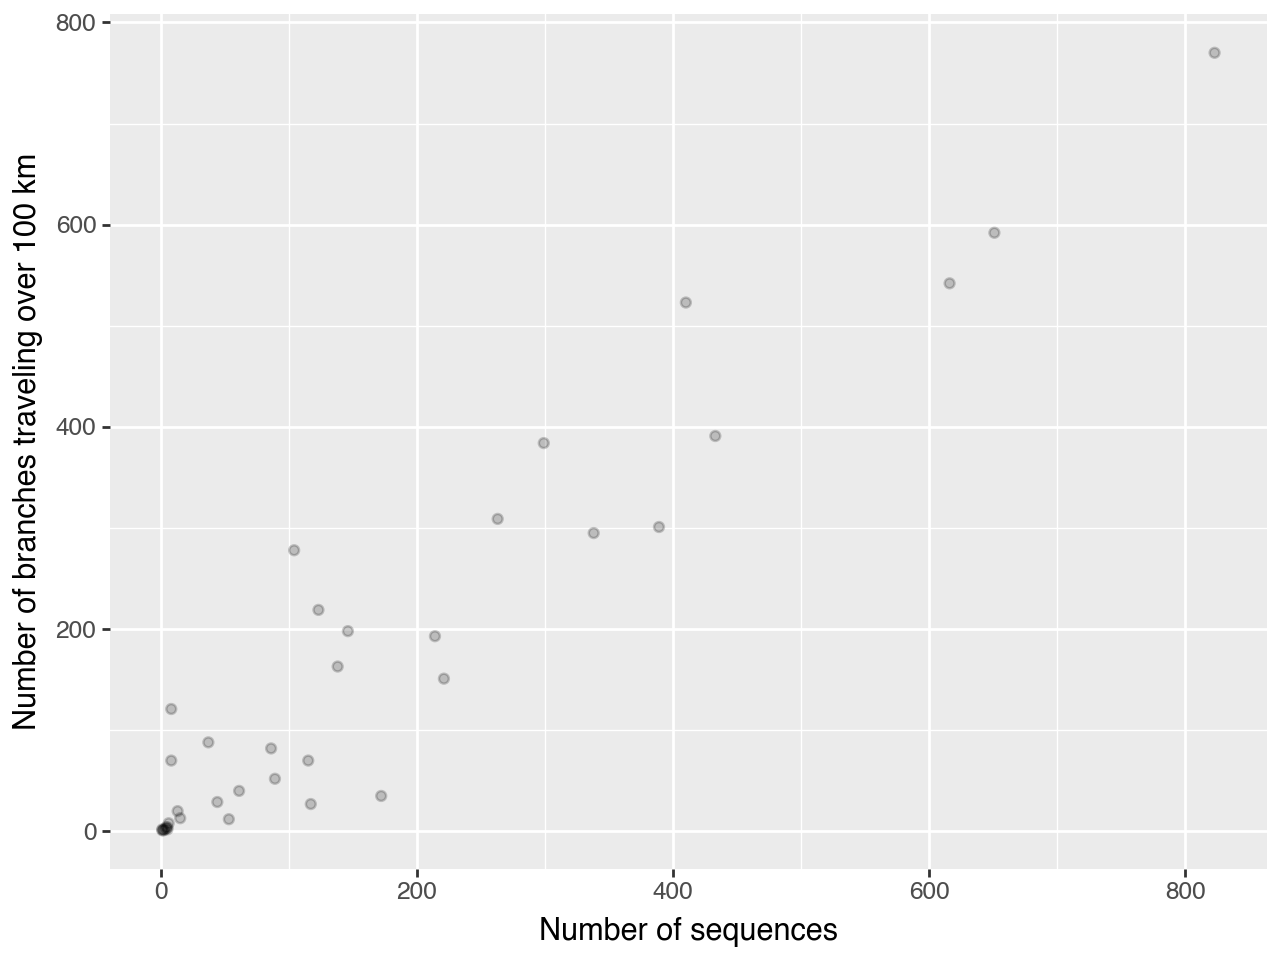

In [8]:
# Plot plot plot!

seq_v_dist = (
    ggplot(dfdf, aes(x = "number_sequences", y = "branches_over100"))
    + geom_point(alpha = 0.2)
    + labs(x = "Number of sequences", y = "Number of branches traveling over 100 km")
)

seq_v_dist.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 23 rows containing missing values.


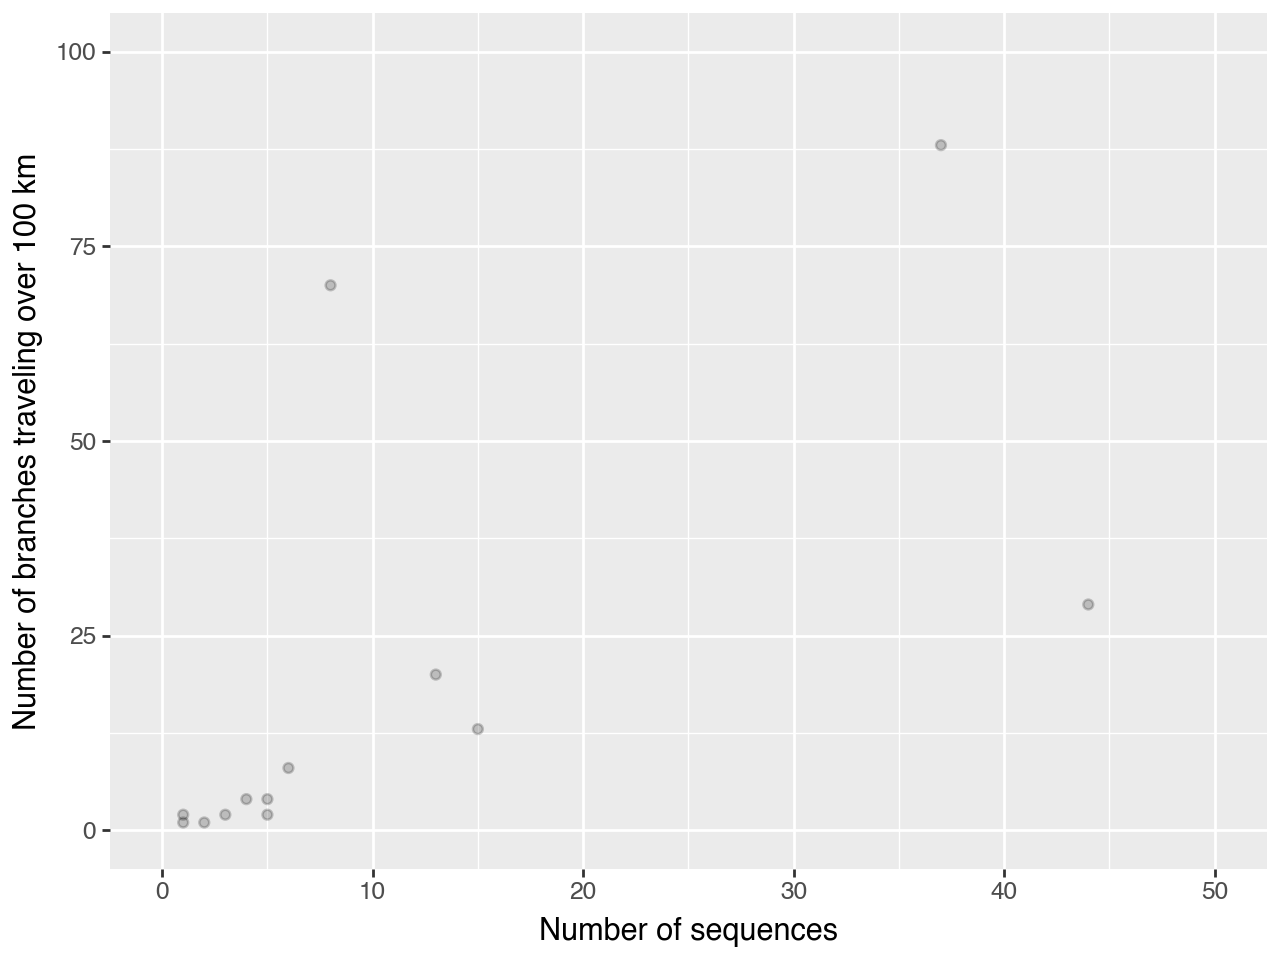

In [9]:
seq_v_dist_zoomed = (
    ggplot(dfdf, aes(x = "number_sequences", y = "branches_over100"))
    + geom_point(alpha = 0.2)
    + ylim(0,100)
    + xlim(0,50)
    + labs(x = "Number of sequences", y = "Number of branches traveling over 100 km")
)

seq_v_dist_zoomed.show()

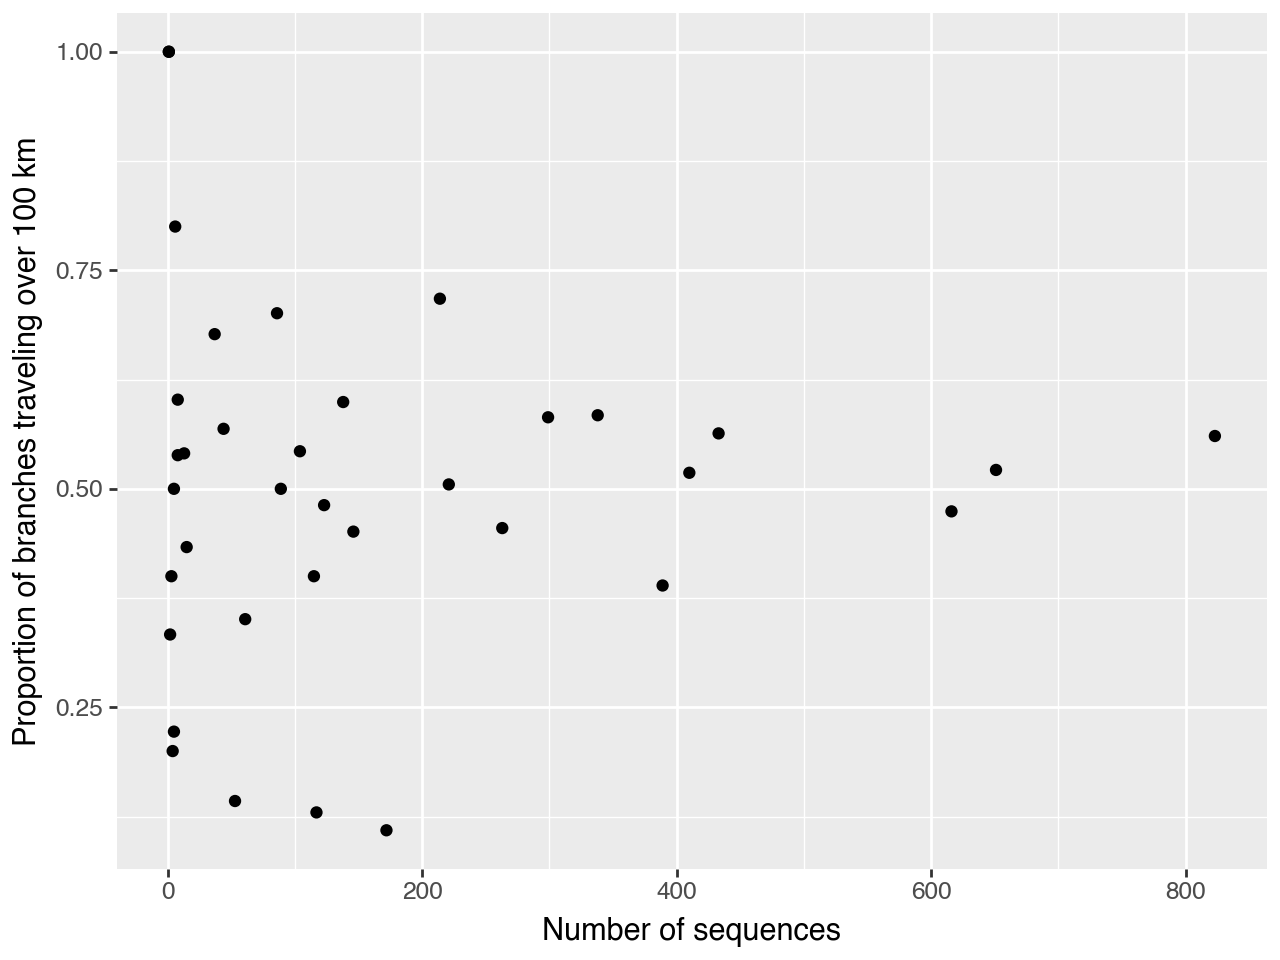

In [10]:
seq_v_prop = (
    ggplot(dfdf, aes(x = "number_sequences", y = "proportion_over100"))
    + geom_point()
    + labs(x = "Number of sequences", y = "Proportion of branches traveling over 100 km")
)

seq_v_prop.show()

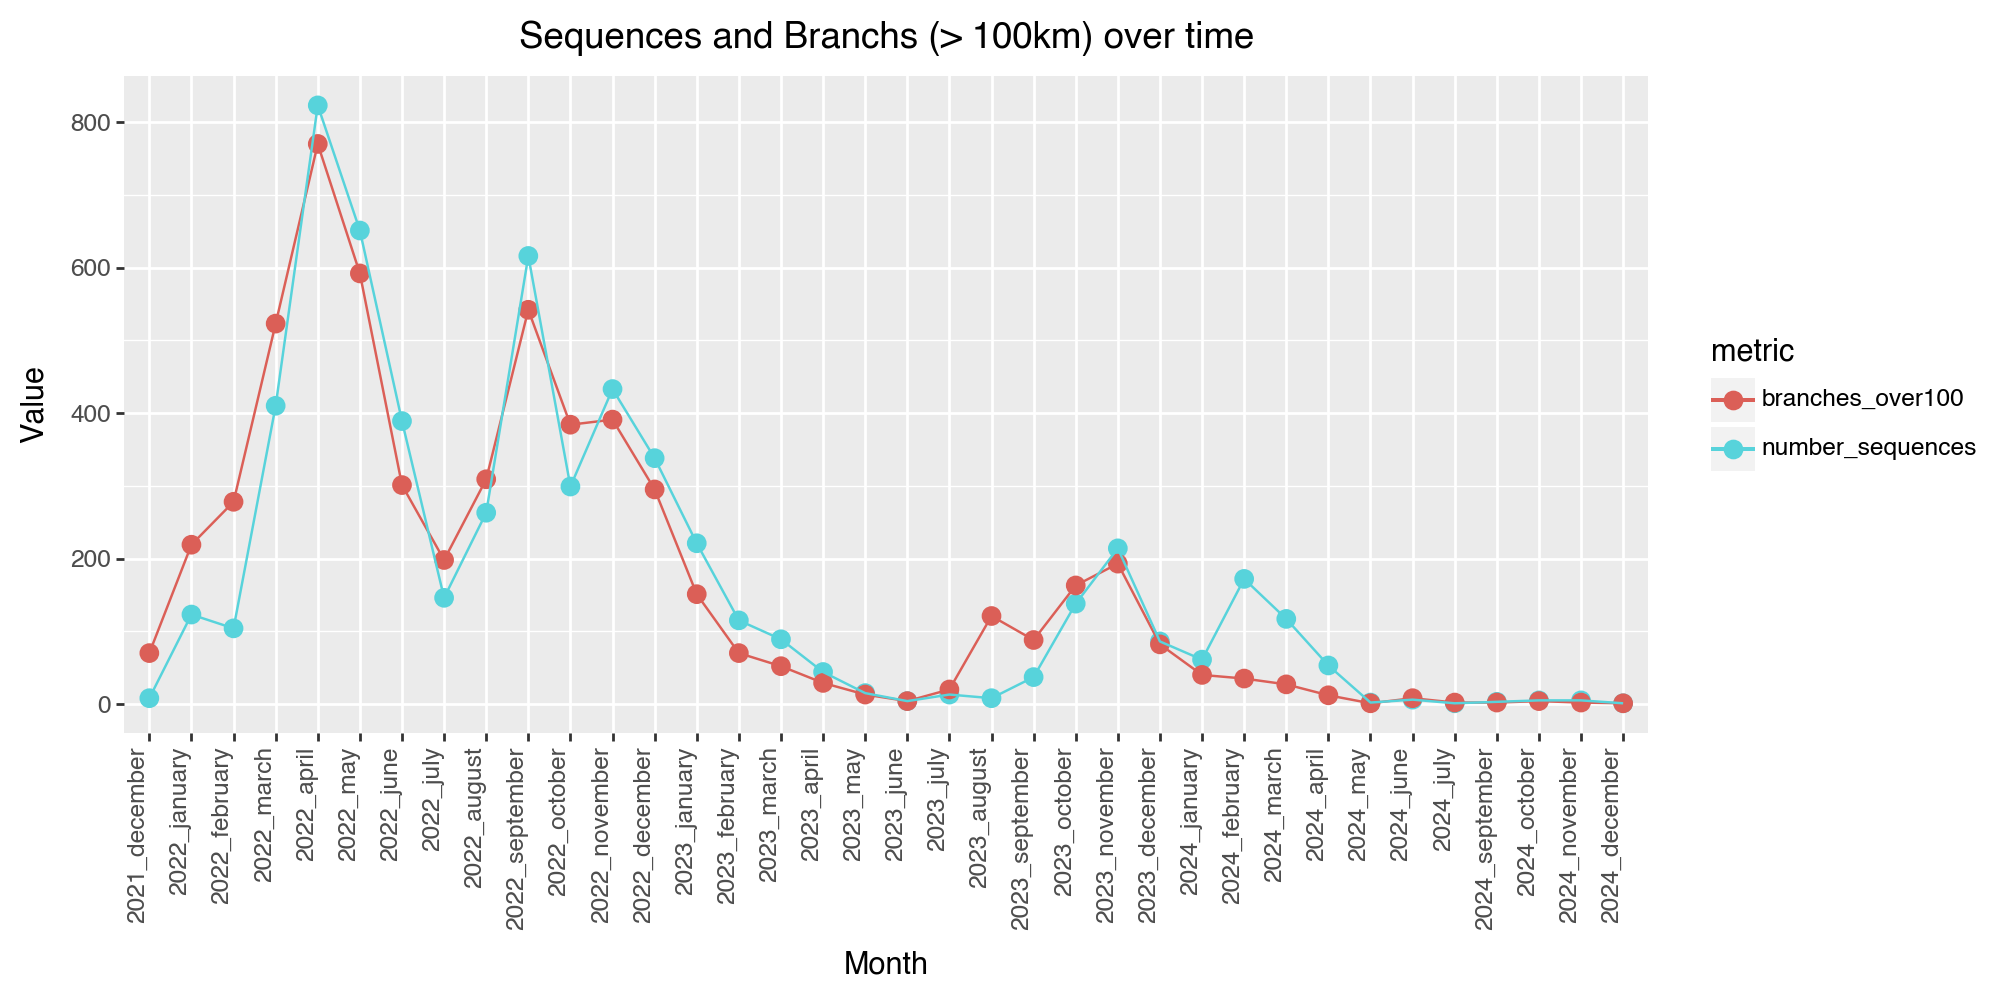

In [18]:
new_index_dfdf = dfdf.reset_index()

df_long = pd.melt(
    new_index_dfdf,
    id_vars=["month_year"],
    value_vars=["number_sequences", "branches_over100"],
    var_name="metric",
    value_name="value"
)

month_order = ["2021_september", "2021_october","2021_november","2021_december", "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
               "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december","2023_january", "2023_february", "2023_march", "2023_april", 
               "2023_may", "2023_june", "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", "2024_january", "2024_february", 
               "2024_march", "2024_april", "2024_may", "2024_june","2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]

df_long["month_year"] = pd.Categorical(
    df_long["month_year"],
    categories=month_order,
    ordered=True
)

plot = (
    ggplot(df_long, aes(x="month_year", y="value", color="metric")) 
    # + geom_bar(stat="identity", position=position_dodge()) 
    + geom_point(stat = "identity", size = 3)
    + geom_line(aes(group="metric"), stat = "identity")
    + labs(x="Month", y="Value", title="Sequences and Branchs (> 100km) over time") 
    + theme(axis_text_x=element_text(rotation=90, hjust=1), figure_size = (10, 5))
)

plot.show()